# 3 · The model learns: a Gaussian process

An interpolation (Lagrange, Newton, splines) draws **one** curve through the measured points and says nothing about how
reliable it is in between. A **Gaussian process (GP)** does the same job and also returns an **uncertainty** σ:
small near a measurement, large far from any measurement. That uncertainty is what the next notebook uses to choose
experiments.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # use the local package without installing it
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nanobo as nb

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
lab = nb.VirtualLab(seed=1)
X = nb.latin_hypercube(12, seed=3)
size, disp = lab.run(X)
y = nb.desirability_score(size, disp)
U = nb.to_unit(X)

gp = nb.make_gp().fit(U, y)
print(gp.kernel_)

1.27**2 * Matern(length_scale=[0.175, 0.787, 5], nu=2.5) + WhiteKernel(noise_level=1e-05)


## Reading the learned kernel

`C × Matern(length_scale=[ℓ1, ℓ2, ℓ3]) + WhiteKernel(noise)`

| symbol | meaning |
|---|---|
| C | how large the score variations are (scores are normalised, so ≈ 1 is normal) |
| ℓ1, ℓ2, ℓ3 | how far each variable (0–1 scale) must move before the score changes: **small ℓ = strong effect** |
| noise | the part of the scatter attributed to experimental noise |

A length that hits its upper bound (5) means *no visible effect* of that variable **in these data**.

In [3]:
h = nb.describe(gp)
pd.Series(h["length_scales"], index=nb.SHORT, name="length scale ℓ (0-1 units)").round(3)

conc_M         0.175
ratio_OA_Fe    0.787
temp_C         5.000
Name: length scale ℓ (0-1 units), dtype: float64

A warning in action: the virtual lab *does* depend strongly on temperature (the best ligand ratio moves with it),
yet with 12 experiments the model may report little or no temperature effect. With few data, length scales are a
**hint, not a conclusion**: check them again as the dataset grows.

In [4]:
print(f"learned noise (score units, 1 sd): {h['noise_sd_score']:.3f}")

learned noise (score units, 1 sd): 0.001


## Prediction and uncertainty along one variable

We vary one variable and keep the two others at the best recipe found so far.

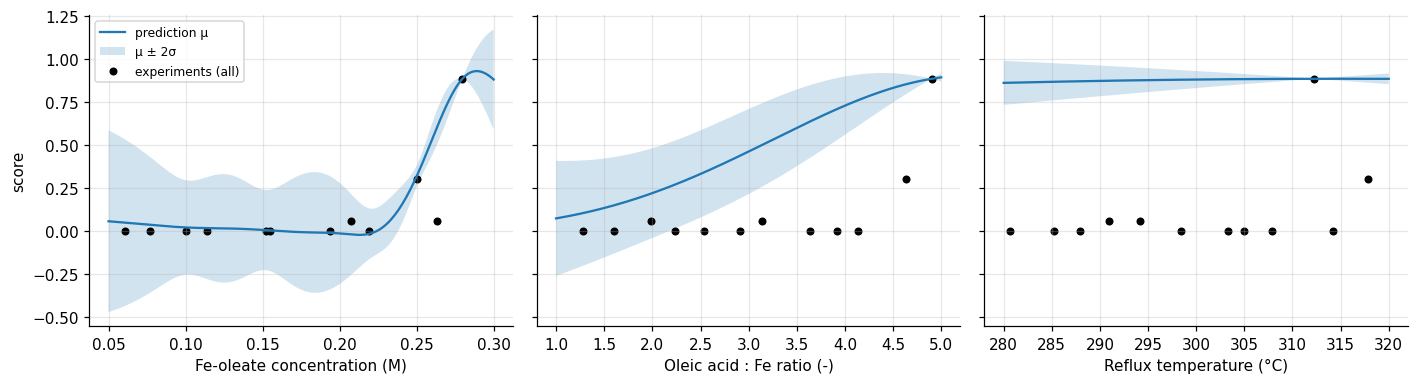

In [5]:
best = U[np.argmax(y)]
grid = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for k, ax in enumerate(axes):
    G = np.tile(best, (len(grid), 1)); G[:, k] = grid
    mu, sd = gp.predict(G, return_std=True)
    xs = nb.from_unit(G)[:, k]
    ax.plot(xs, mu, label="prediction μ")
    ax.fill_between(xs, mu - 2 * sd, mu + 2 * sd, alpha=0.2, label="μ ± 2σ")
    ax.scatter(X[:, k], y, c="k", s=18, label="experiments (all)")
    ax.set_xlabel(f"{nb.NAMES[k]} ({nb.VARIABLES[k][1] or '-'})")
axes[0].set_ylabel("score"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

*(The black points come from the whole 3-D space, so they do not have to lie on a 1-D slice.)*

## Noise: the model needs repeats to see it

The GP can only tell noise from real effects if the **same recipe is repeated**. Below, the same budget of
experiments is fitted twice: once with all-different recipes, once with four repeats of the centre point.
The "true" noise of the score is measured directly by repeating one recipe many times in the virtual lab.

In [6]:
def learned_noise(n_distinct, n_repeats, seed):
    lab = nb.VirtualLab(seed=seed)
    X = nb.latin_hypercube(n_distinct, seed=seed)
    if n_repeats:
        X = np.vstack([X, np.repeat(nb.centre_point(), n_repeats, axis=0)])
    y = nb.desirability_score(*lab.run(X))
    return nb.describe(nb.make_gp(seed=seed).fit(nb.to_unit(X), y))["noise_sd_score"]

ref = nb.VirtualLab(seed=99)
xc = np.repeat(nb.from_unit([[0.7, 0.8, 0.75]]), 400, axis=0)   # a recipe in a sloped region
true_sd = nb.desirability_score(*ref.run(xc)).std()

rows = []
for seed in range(8):
    rows.append({"seed": seed, "16 distinct": learned_noise(16, 0, seed),
                 "12 distinct + 4 centre repeats": learned_noise(12, 4, seed)})
res = pd.DataFrame(rows).set_index("seed")
print(f"noise sd measured by 400 repeats at one recipe: {true_sd:.3f}")
res.round(3)

noise sd measured by 400 repeats at one recipe: 0.129


,16 distinct,12 distinct + 4 centre repeats
seed,,
0,0.001,0.105
1,0.001,0.128
2,0.001,0.057
3,0.001,0.054
4,0.001,0.160
5,0.000,0.153
6,0.145,0.140
7,0.000,0.125


Read the table with care: the score noise depends on *where* you are (it is largest where the score is steep),
so there is no single "true" value. The point is the **spread** of the estimates: without repeats the learned noise
often collapses to its lower bound, and the model becomes over-confident.

## Quality control: a flagged experiment counts less

Suppose one synthesis went wrong without anyone noticing (a pipetting error, a bubble in the measurement cell):
the table now links a recipe to a result it did not produce, and the model learns a false relation (*label noise*).
The dangerous case is a **false positive**: a poor recipe recorded with an excellent score, which the optimiser would
then chase. If a quality check flags the experiment, we keep it in the table but give it a large **per-point noise**
`alpha`, so the GP trusts it less.

In [7]:
y_bad = y.copy()
i_bad = int(np.argmin(y))          # a poor recipe...
y_bad[i_bad] = 0.95                # ...recorded with an excellent score

for a in [None, 0.5, 2.0]:
    alpha = 1e-6 if a is None else np.where(np.arange(len(y)) == i_bad, a, 1e-6)
    pred = nb.make_gp(alpha=alpha).fit(U, y_bad).predict(U[[i_bad]])[0]
    label = "no QC flag" if a is None else f"QC flag, alpha = {a}"
    print(f"{label:22s} -> predicted score at that recipe: {pred:.2f}   (recorded 0.95, true {y[i_bad]:.2f})")

no QC flag             -> predicted score at that recipe: 0.95   (recorded 0.95, true 0.00)
QC flag, alpha = 0.5   -> predicted score at that recipe: 0.59   (recorded 0.95, true 0.00)


QC flag, alpha = 2.0   -> predicted score at that recipe: 0.28   (recorded 0.95, true 0.00)


## Take-aways

* A GP gives **μ and σ for any recipe**; σ is small near data and large far from it.
* One length scale per variable tells **which variables matter** — a hint with few data, not a conclusion.
* Without repeated recipes the **noise is underestimated**: plan centre points from round 0.
* `alpha` lets flagged experiments stay in the table while **counting less**.